# Projet Fil Rouge - indicateurs de naissance en France
### Mcharek, Marwa, 2026

## Data Cleaning

In [59]:
import pandas as pd
# On importe pandas pour lire, nettoyer et analyser les données.

df = pd.read_excel(
    "../data/raw/naissances.xlsx",
    sheet_name=1,
    skiprows=5,
    header=[0, 1]
)
# On lit le fichier Excel naissances.xlsx.
# sheet_name=1 signifie qu’on lit la deuxième feuille du fichier.
# skiprows=5 permet d’ignorer les lignes de titre/description.
# header=[0, 1] indique que les noms de colonnes sont sur deux lignes.

new_columns = []
# On crée une liste vide pour stocker les nouveaux noms de colonnes.

for col in df.columns:
    # On parcourt chaque colonne du tableau.

    niveau_1 = str(col[0]).strip()
    # On récupère le premier niveau du nom de colonne, par exemple l’année 2012.

    niveau_2 = str(col[1]).strip()
    # On récupère le deuxième niveau, par exemple naissances totales.

    if "Unnamed" in niveau_1 and "Unnamed" in niveau_2:
        new_columns.append("a_supprimer")
        # Si les deux niveaux sont vides/inutiles, on marque la colonne à supprimer.

    elif "Unnamed" in niveau_1:
        new_columns.append(niveau_2)
        # Si le premier niveau est vide, on garde seulement le deuxième niveau.

    elif "Unnamed" in niveau_2:
        new_columns.append(niveau_1)
        # Si le deuxième niveau est vide, on garde seulement le premier niveau.

    else:
        new_columns.append(f"{niveau_1}_{niveau_2}")
        # Sinon, on combine les deux niveaux : année + type d’indicateur.

df.columns = new_columns
# On remplace les anciens noms de colonnes par les nouveaux noms propres.

df = df.drop(columns=["a_supprimer"], errors="ignore")
# On supprime les colonnes inutiles repérées plus haut.

df.columns = (
    df.columns
    .str.replace(" ", "_")
    .str.replace("'", "_")
    .str.lower()
)
# On nettoie les noms : espaces remplacés par _, apostrophes remplacées, tout en minuscules.

df.head()
# On affiche les 5 premières lignes pour vérifier le résultat.

,zone_géographique,2012_naissances_totales,2012_naissances_vivantes,2013_naissances_totales,2013_naissances_vivantes,2014_naissances_totales,2014_naissances_vivantes,2015_naissances_totales,2015_naissances_vivantes,2016_naissances_totales,...,2019_naissances_totales,2019_naissances_vivantes,2020_naissances_totales,2020_naissances_vivantes,2021_naissances_totales,2021_naissances_vivantes,2022_naissances_totales,2022_naissances_vivantes,2023_naissances_totales,2023_naissances_vivantes
0,Auvergne - Rhône-Alpes,97162.0,96344.0,95854.0,95073.0,96683.0,95926.0,94586.0,93854.0,92364.0,...,89174.0,88514.0,86542.0,85873.0,87069.0,86382.0,84877.0,84219.0,78411.0,77821.0
1,Bourgogne - Franche-Comté,31467.0,31181.0,30706.0,30459.0,30447.0,30199.0,29532.0,29295.0,28553.0,...,26304.0,26086.0,25836.0,25632.0,25558.0,25314.0,24979.0,24758.0,23348.0,23160.0
2,Bretagne,36740.0,36457.0,35861.0,35559.0,35251.0,34971.0,33712.0,33445.0,32990.0,...,31518.0,31276.0,31238.0,30991.0,32088.0,31826.0,31261.0,30991.0,29113.0,28861.0
3,Centre - Val de Loire,30217.0,29917.0,29419.0,29167.0,29225.0,28984.0,27955.0,27705.0,27478.0,...,26055.0,25823.0,25506.0,25284.0,25582.0,25382.0,25375.0,25175.0,23129.0,22906.0
4,Corse,2995.0,2960.0,2920.0,2887.0,3022.0,2981.0,2873.0,2842.0,2922.0,...,2875.0,2848.0,2682.0,2662.0,2743.0,2722.0,2744.0,2720.0,2513.0,2487.0


In [60]:
#Ensuite ajoute ces cellules de contrôle :

In [61]:
df.shape
# Affiche le nombre de lignes et de colonnes.

(119, 25)

In [62]:
df.info()
# Affiche les types des colonnes et les valeurs non manquantes.

<class 'pandas.DataFrame'>
RangeIndex: 119 entries, 0 to 118
Data columns (total 25 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   zone_géographique         118 non-null    str    
 1   2012_naissances_totales   117 non-null    float64
 2   2012_naissances_vivantes  117 non-null    float64
 3   2013_naissances_totales   117 non-null    float64
 4   2013_naissances_vivantes  117 non-null    float64
 5   2014_naissances_totales   117 non-null    float64
 6   2014_naissances_vivantes  117 non-null    float64
 7   2015_naissances_totales   117 non-null    float64
 8   2015_naissances_vivantes  117 non-null    float64
 9   2016_naissances_totales   117 non-null    float64
 10  2016_naissances_vivantes  117 non-null    float64
 11  2017_naissances_totales   117 non-null    object 
 12  2017_naissances_vivantes  117 non-null    object 
 13  2018_naissances_totales   117 non-null    float64
 14  2018_naissances_vivan

In [63]:
# Conversion des colonnes 2017 en numérique.
# Ces colonnes avaient été importées en type object.
df["2017_naissances_totales"] = pd.to_numeric(
    df["2017_naissances_totales"],
    errors="coerce"
)

df["2017_naissances_vivantes"] = pd.to_numeric(
    df["2017_naissances_vivantes"],
    errors="coerce"
)

In [64]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119 entries, 0 to 118
Data columns (total 25 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   zone_géographique         118 non-null    str    
 1   2012_naissances_totales   117 non-null    float64
 2   2012_naissances_vivantes  117 non-null    float64
 3   2013_naissances_totales   117 non-null    float64
 4   2013_naissances_vivantes  117 non-null    float64
 5   2014_naissances_totales   117 non-null    float64
 6   2014_naissances_vivantes  117 non-null    float64
 7   2015_naissances_totales   117 non-null    float64
 8   2015_naissances_vivantes  117 non-null    float64
 9   2016_naissances_totales   117 non-null    float64
 10  2016_naissances_vivantes  117 non-null    float64
 11  2017_naissances_totales   116 non-null    float64
 12  2017_naissances_vivantes  116 non-null    float64
 13  2018_naissances_totales   117 non-null    float64
 14  2018_naissances_vivan

In [65]:
df.isna().sum()
# Compte les valeurs manquantes colonne par colonne.

zone_géographique           1
2012_naissances_totales     2
2012_naissances_vivantes    2
2013_naissances_totales     2
2013_naissances_vivantes    2
2014_naissances_totales     2
2014_naissances_vivantes    2
2015_naissances_totales     2
2015_naissances_vivantes    2
2016_naissances_totales     2
2016_naissances_vivantes    2
2017_naissances_totales     3
2017_naissances_vivantes    3
2018_naissances_totales     2
2018_naissances_vivantes    2
2019_naissances_totales     2
2019_naissances_vivantes    2
2020_naissances_totales     2
2020_naissances_vivantes    2
2021_naissances_totales     2
2021_naissances_vivantes    2
2022_naissances_totales     2
2022_naissances_vivantes    2
2023_naissances_totales     2
2023_naissances_vivantes    2
dtype: int64

In [66]:
df[df.isna().any(axis=1)]
# Affiche uniquement les lignes contenant au moins une valeur manquante.
# any(axis=1) signifie :
# "au moins une cellule vide sur la ligne".

,zone_géographique,2012_naissances_totales,2012_naissances_vivantes,2013_naissances_totales,2013_naissances_vivantes,2014_naissances_totales,2014_naissances_vivantes,2015_naissances_totales,2015_naissances_vivantes,2016_naissances_totales,...,2019_naissances_totales,2019_naissances_vivantes,2020_naissances_totales,2020_naissances_vivantes,2021_naissances_totales,2021_naissances_vivantes,2022_naissances_totales,2022_naissances_vivantes,2023_naissances_totales,2023_naissances_vivantes
14,Guadeloupe,5142.0,5057.0,5058.0,4972.0,4866.0,4787.0,4603.0,4498.0,4537.0,...,4506.0,4438.0,4666.0,4578.0,4298.0,4217.0,4089.0,4014.0,3914.0,3845.0
117,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
118,"**En 2017, les données du PMSI sont incomplète...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [67]:
df.tail()
# Affiche les 5 dernières lignes du tableau.
# Permet de vérifier que les lignes 117 et 118
# sont bien les lignes de commentaire du fichier.

,zone_géographique,2012_naissances_totales,2012_naissances_vivantes,2013_naissances_totales,2013_naissances_vivantes,2014_naissances_totales,2014_naissances_vivantes,2015_naissances_totales,2015_naissances_vivantes,2016_naissances_totales,...,2019_naissances_totales,2019_naissances_vivantes,2020_naissances_totales,2020_naissances_vivantes,2021_naissances_totales,2021_naissances_vivantes,2022_naissances_totales,2022_naissances_vivantes,2023_naissances_totales,2023_naissances_vivantes
114,Seine-Saint-Denis,28763.0,28447.0,28736.0,28426.0,29619.0,29276.0,29556.0,29235.0,29421.0,...,28579.0,28312.0,28078.0,27775.0,26554.0,26282.0,26527.0,26258.0,25320.0,25064.0
115,Val-de-Marne,20999.0,20793.0,20731.0,20548.0,21588.0,21367.0,21082.0,20904.0,20922.0,...,20733.0,20539.0,20009.0,19835.0,19740.0,19570.0,19101.0,18951.0,17818.0,17654.0
116,Val-d'Oise,19510.0,19335.0,19507.0,19318.0,19695.0,19483.0,19616.0,19394.0,19671.0,...,19805.0,19617.0,19148.0,18963.0,19256.0,19076.0,19173.0,18994.0,17970.0,17764.0
117,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
118,"**En 2017, les données du PMSI sont incomplète...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [68]:
df = df.iloc[:-2]
# On supprime les 2 dernières lignes :
# - ligne vide
# - note PMSI

In [69]:
df.shape

# Vérifie le nombre de lignes et de colonnes.

(117, 25)

In [70]:
df.isna().sum()

# Vérifie les valeurs manquantes après nettoyage.

zone_géographique           0
2012_naissances_totales     0
2012_naissances_vivantes    0
2013_naissances_totales     0
2013_naissances_vivantes    0
2014_naissances_totales     0
2014_naissances_vivantes    0
2015_naissances_totales     0
2015_naissances_vivantes    0
2016_naissances_totales     0
2016_naissances_vivantes    0
2017_naissances_totales     1
2017_naissances_vivantes    1
2018_naissances_totales     0
2018_naissances_vivantes    0
2019_naissances_totales     0
2019_naissances_vivantes    0
2020_naissances_totales     0
2020_naissances_vivantes    0
2021_naissances_totales     0
2021_naissances_vivantes    0
2022_naissances_totales     0
2022_naissances_vivantes    0
2023_naissances_totales     0
2023_naissances_vivantes    0
dtype: int64

In [71]:
df.tail()
# Vérification finale du DataFrame après nettoyage.
# Les lignes de commentaire ont été supprimées.

,zone_géographique,2012_naissances_totales,2012_naissances_vivantes,2013_naissances_totales,2013_naissances_vivantes,2014_naissances_totales,2014_naissances_vivantes,2015_naissances_totales,2015_naissances_vivantes,2016_naissances_totales,...,2019_naissances_totales,2019_naissances_vivantes,2020_naissances_totales,2020_naissances_vivantes,2021_naissances_totales,2021_naissances_vivantes,2022_naissances_totales,2022_naissances_vivantes,2023_naissances_totales,2023_naissances_vivantes
112,Essonne,18615.0,18396.0,18599.0,18429.0,18997.0,18816.0,19128.0,18935.0,18747.0,...,18585.0,18397.0,18482.0,18286.0,18538.0,18353.0,18385.0,18223.0,17263.0,17084.0
113,Hauts-de-Seine,24899.0,24647.0,24904.0,24689.0,25015.0,24794.0,24360.0,24149.0,24370.0,...,22905.0,22717.0,21908.0,21716.0,22010.0,21838.0,21079.0,20896.0,19863.0,19713.0
114,Seine-Saint-Denis,28763.0,28447.0,28736.0,28426.0,29619.0,29276.0,29556.0,29235.0,29421.0,...,28579.0,28312.0,28078.0,27775.0,26554.0,26282.0,26527.0,26258.0,25320.0,25064.0
115,Val-de-Marne,20999.0,20793.0,20731.0,20548.0,21588.0,21367.0,21082.0,20904.0,20922.0,...,20733.0,20539.0,20009.0,19835.0,19740.0,19570.0,19101.0,18951.0,17818.0,17654.0
116,Val-d'Oise,19510.0,19335.0,19507.0,19318.0,19695.0,19483.0,19616.0,19394.0,19671.0,...,19805.0,19617.0,19148.0,18963.0,19256.0,19076.0,19173.0,18994.0,17970.0,17764.0


In [72]:
# Une valeur manquante subsiste pour l'année 2017.
# Cela est cohérent avec la note du fichier PMSI indiquant
# que les données 2017 sont incomplètes.

In [ ]:
df.describe()  # Permet d'obtenir un résumé statistique des données numériques :
               # count = nombre de valeurs
               # mean = moyenne
               # std = écart-type
               # min / max = valeurs extrêmes
               # 25%, 50%, 75% = quartiles

,2012_naissances_totales,2012_naissances_vivantes,2013_naissances_totales,2013_naissances_vivantes,2014_naissances_totales,2014_naissances_vivantes,2015_naissances_totales,2015_naissances_vivantes,2016_naissances_totales,2016_naissances_vivantes,...,2019_naissances_totales,2019_naissances_vivantes,2020_naissances_totales,2020_naissances_vivantes,2021_naissances_totales,2021_naissances_vivantes,2022_naissances_totales,2022_naissances_vivantes,2023_naissances_totales,2023_naissances_vivantes
count,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000,...,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000
mean,28080.487179,27822.709402,27776.461538,27528.641026,27747.700855,27505.111111,27067.692308,26829.290598,26565.213675,26331.333333,...,25461.641026,25247.726496,24867.487179,24648.888889,25037.487179,24817.358974,24526.914530,24313.179487,22801.589744,22602.555556
std,106339.883568,105368.273496,105237.215813,104303.976724,105159.236033,104243.339245,102525.758722,101628.538126,100615.564339,99734.252390,...,96398.305541,95593.735526,94139.719560,93317.924327,94691.447589,93865.129554,92753.382408,91950.933818,86199.378033,85451.016940
min,701.000000,699.000000,654.000000,653.000000,660.000000,652.000000,694.000000,685.000000,662.000000,659.000000,...,584.000000,580.000000,518.000000,513.000000,611.000000,609.000000,587.000000,581.000000,557.000000,553.000000
25%,3527.000000,3498.000000,3469.000000,3442.000000,3382.000000,3355.000000,3232.000000,3208.000000,3210.000000,3187.000000,...,2982.000000,2965.000000,2942.000000,2918.000000,2940.000000,2915.000000,2910.000000,2889.000000,2690.000000,2670.000000
50%,6809.000000,6755.000000,6710.000000,6648.000000,6688.000000,6643.000000,6561.000000,6497.000000,6384.000000,6329.000000,...,5967.000000,5931.000000,5971.000000,5924.000000,6002.000000,5949.000000,5828.000000,5778.000000,5405.000000,5372.000000
75%,16470.000000,16328.000000,16432.000000,16288.000000,16776.000000,16629.000000,16396.000000,16267.000000,16138.000000,16015.000000,...,15716.000000,15588.000000,15404.000000,15269.000000,15435.000000,15304.000000,15162.000000,15022.000000,14155.000000,14046.000000
max,830758.000000,823085.000000,821598.000000,814216.000000,820800.000000,813583.000000,801271.000000,794160.000000,786629.000000,779655.000000,...,754509.000000,748121.000000,736867.000000,730337.000000,742341.000000,735760.000000,727143.000000,720752.000000,676380.000000,670434.000000


In [ ]:
df.to_csv(
    "../data/processed/naissances_clean.csv",
    index=False
)

# Sauvegarde le DataFrame nettoyé dans le dossier processed.
# index=False évite d'ajouter une colonne d'index inutile.

## Structuration géographique des données

In [ ]:
df["zone_géographique"].tolist()

['Auvergne -  Rhône-Alpes',
 'Bourgogne -  Franche-Comté',
 'Bretagne',
 'Centre -  Val de Loire',
 'Corse',
 'Grand Est',
 'Hauts-de-France',
 'Ile-de-France',
 'Normandie',
 'Nouvelle-Aquitaine',
 'Occitanie',
 'Pays de la Loire',
 "Provence - Alpes - Côte d'Azur",
 'Total métropole',
 'Guadeloupe',
 'Guyane',
 'La Réunion',
 'Martinique',
 'Mayotte',
 'Total DROM',
 'Total France entière',
 'Ain',
 'Aisne',
 'Allier',
 'Alpes-de-Haute-Provence',
 'Hautes-Alpes',
 'Alpes-Maritimes',
 'Ardèche',
 'Ardennes',
 'Ariège',
 'Aube',
 'Aude',
 'Aveyron',
 'Bouches-du-Rhône',
 'Calvados',
 'Cantal',
 'Charente',
 'Charente-Maritime',
 'Cher',
 'Corrèze',
 "Côte-d'Or",
 "Côtes-d'Armor",
 'Creuse',
 'Dordogne',
 'Doubs',
 'Drôme',
 'Eure',
 'Eure-et-Loir',
 'Finistère',
 'Corse-du-Sud',
 'Haute-Corse',
 'Gard',
 'Haute-Garonne',
 'Gers',
 'Gironde',
 'Hérault',
 'Ille-et-Vilaine',
 'Indre',
 'Indre-et-Loire',
 'Isère',
 'Jura',
 'Landes',
 'Loir-et-Cher',
 'Loire',
 'Haute-Loire',
 'Loire-Atla

In [ ]:
# Création du DataFrame France
df_france = df[
    df["zone_géographique"] == "Total France entière"
]

# Conserve uniquement la ligne correspondant à la France entière.
df_france["zone_géographique"].tolist()

['Total France entière']

In [ ]:
# Création du DataFrame Régions
regions = [
    "Auvergne -  Rhône-Alpes",
    "Bourgogne -  Franche-Comté",
    "Bretagne",
    "Centre -  Val de Loire",
    "Corse",
    "Grand Est",
    "Hauts-de-France",
    "Ile-de-France",
    "Normandie",
    "Nouvelle-Aquitaine",
    "Occitanie",
    "Pays de la Loire",
    "Provence - Alpes - Côte d'Azur",
    "Guadeloupe",
    "Guyane",
    "La Réunion",
    "Martinique",
    "Mayotte"
]

df_regions = df[
    df["zone_géographique"].isin(regions)
]

# Conserve uniquement les régions.# Création du DataFrame France
df_regions["zone_géographique"].tolist()

['Auvergne -  Rhône-Alpes',
 'Bourgogne -  Franche-Comté',
 'Bretagne',
 'Centre -  Val de Loire',
 'Corse',
 'Grand Est',
 'Hauts-de-France',
 'Ile-de-France',
 'Normandie',
 'Nouvelle-Aquitaine',
 'Occitanie',
 'Pays de la Loire',
 "Provence - Alpes - Côte d'Azur",
 'Guadeloupe',
 'Guyane',
 'La Réunion',
 'Martinique',
 'Mayotte']

In [ ]:
# Création du DataFrame Départements
df_departements = df[
    ~df["zone_géographique"].isin(regions)
]

# Exclut les régions.

In [ ]:
df_departements = df_departements[
    ~df_departements["zone_géographique"].isin(
        [
            "Total métropole",
            "Total DROM",
            "Total France entière"
        ]
    )
]
df_departements["zone_géographique"].tolist()

['Ain',
 'Aisne',
 'Allier',
 'Alpes-de-Haute-Provence',
 'Hautes-Alpes',
 'Alpes-Maritimes',
 'Ardèche',
 'Ardennes',
 'Ariège',
 'Aube',
 'Aude',
 'Aveyron',
 'Bouches-du-Rhône',
 'Calvados',
 'Cantal',
 'Charente',
 'Charente-Maritime',
 'Cher',
 'Corrèze',
 "Côte-d'Or",
 "Côtes-d'Armor",
 'Creuse',
 'Dordogne',
 'Doubs',
 'Drôme',
 'Eure',
 'Eure-et-Loir',
 'Finistère',
 'Corse-du-Sud',
 'Haute-Corse',
 'Gard',
 'Haute-Garonne',
 'Gers',
 'Gironde',
 'Hérault',
 'Ille-et-Vilaine',
 'Indre',
 'Indre-et-Loire',
 'Isère',
 'Jura',
 'Landes',
 'Loir-et-Cher',
 'Loire',
 'Haute-Loire',
 'Loire-Atlantique',
 'Loiret',
 'Lot',
 'Lot-et-Garonne',
 'Lozère',
 'Maine-et-Loire',
 'Manche',
 'Marne',
 'Haute-Marne',
 'Mayenne',
 'Meurthe-et-Moselle',
 'Meuse',
 'Morbihan',
 'Moselle',
 'Nièvre',
 'Nord',
 'Oise',
 'Orne',
 'Pas-de-Calais',
 'Puy-de-Dôme',
 'Pyrénées-Atlantiques',
 'Hautes-Pyrénées',
 'Pyrénées-Orientales',
 'Bas-Rhin',
 'Haut-Rhin',
 'Rhône',
 'Haute-Saône',
 'Saône-et-Loire',

In [ ]:
# =====================================================
# Structuration géographique des données
# =====================================================

# Les données contiennent :
# - une ligne France entière
# - les régions
# - les départements
#
# Je sépare ces niveaux géographiques
# afin de faciliter les futures analyses
# et visualisations.
print("France :", df_france.shape)
print("Régions :", df_regions.shape)
print("Départements :", df_departements.shape)

France : (1, 25)
Régions : (18, 25)
Départements : (96, 25)


In [ ]:
df_france.to_csv("../data/processed/naissances_france.csv", index=False)

df_regions.to_csv("../data/processed/naissances_regions.csv", index=False)

df_departements.to_csv("../data/processed/naissances_departements.csv", index=False)

In [ ]:
# Vérification finale

print("France")
display(df_france.head())

print("Régions")
display(df_regions.head())

print("Départements")
display(df_departements.head())

France


,zone_géographique,2012_naissances_totales,2012_naissances_vivantes,2013_naissances_totales,2013_naissances_vivantes,2014_naissances_totales,2014_naissances_vivantes,2015_naissances_totales,2015_naissances_vivantes,2016_naissances_totales,...,2019_naissances_totales,2019_naissances_vivantes,2020_naissances_totales,2020_naissances_vivantes,2021_naissances_totales,2021_naissances_vivantes,2022_naissances_totales,2022_naissances_vivantes,2023_naissances_totales,2023_naissances_vivantes
20,Total France entière,830758.0,823085.0,821598.0,814216.0,820800.0,813583.0,801271.0,794160.0,786629.0,...,754509.0,748121.0,736867.0,730337.0,742341.0,735760.0,727143.0,720752.0,676380.0,670434.0


Régions


,zone_géographique,2012_naissances_totales,2012_naissances_vivantes,2013_naissances_totales,2013_naissances_vivantes,2014_naissances_totales,2014_naissances_vivantes,2015_naissances_totales,2015_naissances_vivantes,2016_naissances_totales,...,2019_naissances_totales,2019_naissances_vivantes,2020_naissances_totales,2020_naissances_vivantes,2021_naissances_totales,2021_naissances_vivantes,2022_naissances_totales,2022_naissances_vivantes,2023_naissances_totales,2023_naissances_vivantes
0,Auvergne - Rhône-Alpes,97162.0,96344.0,95854.0,95073.0,96683.0,95926.0,94586.0,93854.0,92364.0,...,89174.0,88514.0,86542.0,85873.0,87069.0,86382.0,84877.0,84219.0,78411.0,77821.0
1,Bourgogne - Franche-Comté,31467.0,31181.0,30706.0,30459.0,30447.0,30199.0,29532.0,29295.0,28553.0,...,26304.0,26086.0,25836.0,25632.0,25558.0,25314.0,24979.0,24758.0,23348.0,23160.0
2,Bretagne,36740.0,36457.0,35861.0,35559.0,35251.0,34971.0,33712.0,33445.0,32990.0,...,31518.0,31276.0,31238.0,30991.0,32088.0,31826.0,31261.0,30991.0,29113.0,28861.0
3,Centre - Val de Loire,30217.0,29917.0,29419.0,29167.0,29225.0,28984.0,27955.0,27705.0,27478.0,...,26055.0,25823.0,25506.0,25284.0,25582.0,25382.0,25375.0,25175.0,23129.0,22906.0
4,Corse,2995.0,2960.0,2920.0,2887.0,3022.0,2981.0,2873.0,2842.0,2922.0,...,2875.0,2848.0,2682.0,2662.0,2743.0,2722.0,2744.0,2720.0,2513.0,2487.0


Départements


,zone_géographique,2012_naissances_totales,2012_naissances_vivantes,2013_naissances_totales,2013_naissances_vivantes,2014_naissances_totales,2014_naissances_vivantes,2015_naissances_totales,2015_naissances_vivantes,2016_naissances_totales,...,2019_naissances_totales,2019_naissances_vivantes,2020_naissances_totales,2020_naissances_vivantes,2021_naissances_totales,2021_naissances_vivantes,2022_naissances_totales,2022_naissances_vivantes,2023_naissances_totales,2023_naissances_vivantes
21,Ain,7295.0,7231.0,7371.0,7316.0,7419.0,7367.0,7065.0,7008.0,7190.0,...,6946.0,6901.0,6877.0,6817.0,7044.0,6993.0,6891.0,6842.0,6326.0,6293.0
22,Aisne,6809.0,6748.0,6633.0,6574.0,6484.0,6430.0,6265.0,6215.0,5871.0,...,5464.0,5406.0,5374.0,5338.0,5374.0,5333.0,5416.0,5362.0,5139.0,5081.0
23,Allier,3303.0,3275.0,3217.0,3192.0,3168.0,3145.0,3031.0,3000.0,3028.0,...,2788.0,2765.0,2621.0,2592.0,2784.0,2763.0,2644.0,2619.0,2494.0,2476.0
24,Alpes-de-Haute-Provence,1542.0,1530.0,1611.0,1600.0,1528.0,1503.0,1486.0,1468.0,1464.0,...,1357.0,1346.0,1315.0,1303.0,1422.0,1415.0,1352.0,1347.0,1270.0,1256.0
25,Hautes-Alpes,1456.0,1438.0,1422.0,1408.0,1406.0,1391.0,1351.0,1340.0,1316.0,...,1249.0,1240.0,1188.0,1172.0,1277.0,1261.0,1249.0,1242.0,1089.0,1083.0


## Data Visualisation
Ici, vous réaliserez vos observations, créerez vos graphes dans un premier temps. Une fois qu'ils seront fait, ils seront à intégrer à votre application Streamlit. Considérez donc cet espace comme un bac à sable avant de vous lancer dans le développement de l'application de Data Visualisation.

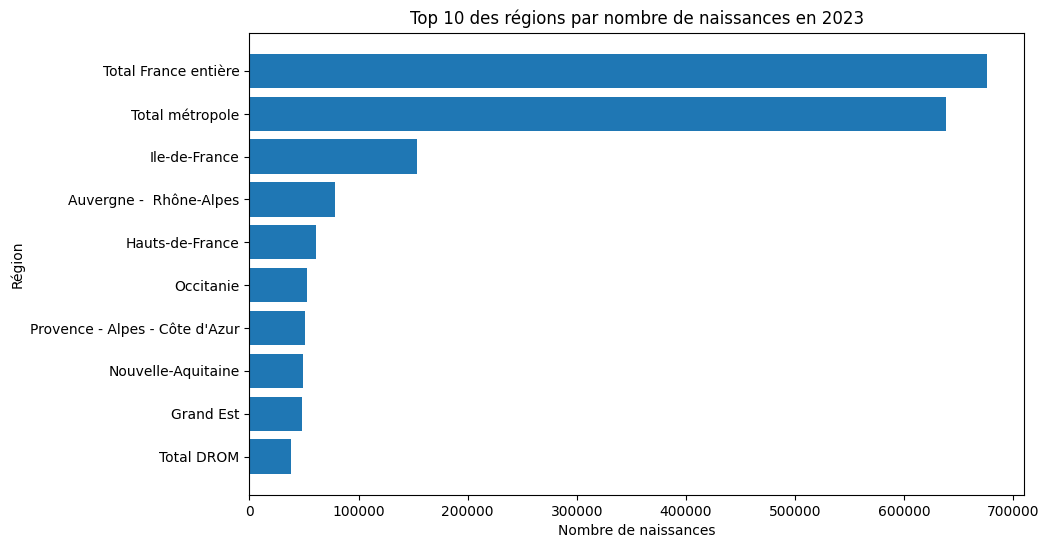

In [ ]:
# Importation de la bibliothèque de visualisation
import matplotlib.pyplot as plt

# =====================================================
# TOP 10 DES RÉGIONS PAR NOMBRE DE NAISSANCES EN 2023
# =====================================================

# Trie le DataFrame selon la colonne
# "2023_naissances_totales"
# du plus grand au plus petit.
top10 = df.sort_values(
    by="2023_naissances_totales",
    ascending=False
)

# Conserve uniquement les 10 premières régions.
top10 = top10.head(10)

# Crée une figure de taille 10 pouces × 6 pouces.
plt.figure(figsize=(10, 6))

# Crée un graphique en barres horizontales.
plt.barh(
    top10["zone_géographique"],       # Nom des régions
    top10["2023_naissances_totales"]  # Nombre de naissances
)

# Ajoute un titre au graphique.
plt.title(
    "Top 10 des régions par nombre de naissances en 2023"
)

# Ajoute le titre de l'axe horizontal.
plt.xlabel(
    "Nombre de naissances"
)

# Ajoute le titre de l'axe vertical.
plt.ylabel(
    "Région"
)

# Inverse l'ordre pour afficher la région
# ayant le plus de naissances en haut du graphique.
plt.gca().invert_yaxis()

# Affiche le graphique.
plt.show()